# Assignment 1: CIFAR-10 classification project

<h2>1. Business understanding</h2>

The goal of this project is to classify color images from the CIFAR-10 dataset into ten different classes using a `Fully Connected Network` (FCN). The models performance will be evaluated using test accuracy and learning curves. The results will also be compared with a `Convolutional Neural Network` (CNN) to investigate how different network architectures affect image classification.

Realistic accuracy for <b>FCN</b> is 50-55% and ambitious accuracy is 57-60%.<br>
Realistic accuracy for <b>CNN</b> is 75-80% and ambitious accuracy is 82-85%.

<h2>2. Data understanding</h2>

The CIFAR-10 dataset contains `60,000 color images` divided into ten classes. Each image has a resolution of `32×32 pixels` and three color channels (red, green, blue). The dataset is divided into 50,000 training images and 10,000 test images.

The classes are:

- 0: airplane
- 1: automobile
- 2: bird
- 3: cat
- 4: deer
- 5: dog
- 6: frog
- 7: horse
- 8: ship
- 9: truck

Here we explore the dataset.

In [1]:
import os
os.environ["KERAS_BACKEND"] = "tensorflow" # choosing the back end, "tensorflow"

import keras
from keras import layers
from keras.layers import Input, Flatten, Dense
from keras.datasets import cifar10
from keras.models import Sequential
from keras.utils import to_categorical

import numpy as np
import matplotlib.pyplot as plt

print(keras.__version__, keras.backend.backend()) # keras library version

3.15.1 tensorflow


In [2]:
(X_train, y_train), (X_test, y_test) = cifar10.load_data() #keras downloads dataset, which has been already divided to test and train data.

In [3]:
print("X_train:", X_train.shape) 
print("y_train:", y_train.shape)
print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (50000, 32, 32, 3)
y_train: (50000, 1)
X_test: (10000, 32, 32, 3)
y_test: (10000, 1)


Above we inspected the datas dimensions. 50,000 training images, each 32×32 pixels with 3 color channels and one integer label (0-9) per image. Same for 10,000 test images.

Next we find a picture example from the data by typing a sample number. Then we are provided with the picture and the class number as a title.

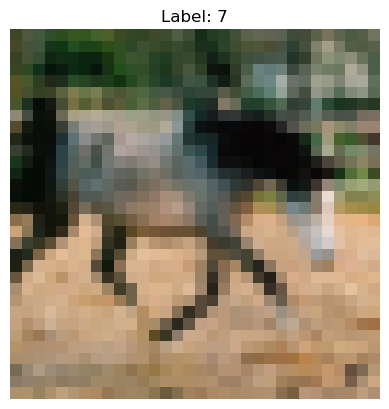

In [4]:
sample_number = 52 #find different images
plt.imshow(X_train[sample_number])
plt.title(f'Label: {y_train[sample_number][0]}')
plt.axis('off')
plt.show()

<h2>3. Data preparation</h2>

CIFAR-10 data was clean from the start, so changes or clean ups were unnecessary. Pixel values are divided by 255, in which case they are in the range 0–1. It ensures better learning. And due to that, type is changed into float because of the division.

The labels are changed into one-hot-form with `to_categorical`.

In [5]:
# Data preparation
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

y_train = to_categorical(y_train, 10)
y_test = to_categorical(y_test, 10)

Next, we check the format of the label.

In [6]:
y_train[52]

array([0., 0., 0., 0., 0., 0., 0., 1., 0., 0.])

Previously the inspected label was 7, and now it is successfully converted into one-hot-form.

<h2>4. Modeling</h2>

<h3>Fully Connected Network</h3>

We continue by flattening each image into 3,072 values, pass them trough 2 hidden layers to learn patterns and outputs probabilities for the 10 classes with softmax. Both hidden layers use the ReLU activation function. The model is then compiled with "adam" optimizer as trought testing, we found it to be more accurate compared to the alternative "rmsprop" optimizer.

The model is trained for 18 epochs in batches of 32 images (because the size of the data), using 10% of the training data for validation and the training history is saved for plotting learning curves.

In [7]:
fcn_model = Sequential([
    Input(shape=(32, 32, 3)), #image shape, 3 for the colors
    Flatten(), #image to one dimencional vector 32×32×3 = 3,072
    Dense(512, activation='relu'), #learns patterns from the pixel values using 512 neurons
    Dense(256, activation='relu'), #256 neurons, each looking at all 512 outputs of the previous layer
    Dense(10, activation='softmax') #produces probabilities for the 10 possible classes
    ], name="fcn_model", )

In [8]:
#compiling. tells how the model should be taught
fcn_model.compile(optimizer='adam', #rmsprop (alternative)
              loss='categorical_crossentropy', #measures how wrong the model is
              metrics=['accuracy'])

In [9]:
fcn_history = fcn_model.fit( #the model can be trained with the training data
    X_train,
    y_train,
    epochs=18, #how many times model goes trough data
    batch_size=32, #the model updates its weights in batches of 32 images.
    validation_split=0.1 #10% of the training data is used for validation
) 

Epoch 1/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 25s 15ms/step - accuracy: 0.3251 - loss: 1.8681 - val_accuracy: 0.3600 - val_loss: 1.7553
Epoch 2/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.3957 - loss: 1.6821 - val_accuracy: 0.3688 - val_loss: 1.7271
Epoch 3/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.4232 - loss: 1.6060 - val_accuracy: 0.4340 - val_loss: 1.6031
Epoch 4/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 19s 14ms/step - accuracy: 0.4410 - loss: 1.5562 - val_accuracy: 0.4386 - val_loss: 1.5682
Epoch 5/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.4552 - loss: 1.5206 - val_accuracy: 0.4592 - val_loss: 1.5302
Epoch 6/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.4660 - loss: 1.4910 - val_accuracy: 0.4492 - val_loss: 1.5576
Epoch 7/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.4743 - loss: 1.4679 - val_accuracy: 0.4740 - val_loss: 1.5018
Epoch 8/18
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 20s 14ms/step - accuracy: 0.4816 -

The FCN model achieved a training accuracy of $\approx$53% and a loss of $\approx$1.3 after 18 epochs of training. On the validation set, the accuracy was $\approx$49% and the validation loss was $\approx$1.46.  

Many different values for the number of epochs and other parameters were also tested. Initially, the FCN model was trained for 30 epochs. The highest validation accuracy of 50.12% was achieved at epoch 18. Towards the end of training, the training accuracy continued to increase (reaching 57.82%), but the validation accuracy dropped to $\approx$48% by epoch 30. Therefore, the 18 epochs was selected.

<h3>Convolutional Neural Network</h3>

Different CNN architectures are explored and evaluated using validation data. After that, the model with best performance is selected for final evaluation with separate test data.

In [10]:
cnn_model_01 = Sequential(
    [
        layers.Input((32, 32, 3)),
        
        # 1st convo block
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        # 2nd convo block
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.BatchNormalization(),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        # classification
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(10, activation="softmax"),
    ],
    name="cnn_model_relu_on_convo",
)

cnn_model_01.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn_history_01 = cnn_model_01.fit(X_train, y_train, batch_size=32, epochs=30, validation_split=0.1)

Epoch 1/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 64s 43ms/step - accuracy: 0.4096 - loss: 1.6458 - val_accuracy: 0.5448 - val_loss: 1.2675
Epoch 2/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 60s 43ms/step - accuracy: 0.5632 - loss: 1.2266 - val_accuracy: 0.5692 - val_loss: 1.2469
Epoch 3/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 60s 43ms/step - accuracy: 0.6260 - loss: 1.0617 - val_accuracy: 0.7010 - val_loss: 0.8506
Epoch 4/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 60s 42ms/step - accuracy: 0.6628 - loss: 0.9644 - val_accuracy: 0.5724 - val_loss: 1.2630
Epoch 5/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 60s 43ms/step - accuracy: 0.6786 - loss: 0.9067 - val_accuracy: 0.6846 - val_loss: 0.8954
Epoch 6/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 60s 43ms/step - accuracy: 0.6983 - loss: 0.8607 - val_accuracy: 0.7426 - val_loss: 0.7589
Epoch 7/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 60s 43ms/step - accuracy: 0.7086 - loss: 0.8262 - val_accuracy: 0.7082 - val_loss: 0.8295
Epoch 8/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 82s 42ms/step - accuracy: 0.7228 -

The first model achieved a training accuracy of 81.19%, a training loss of 0.5387, a validation accuracy of 79.62%, and a validation loss of 0.6120. 

In [11]:
cnn_model_02 = Sequential(
    [
        layers.Input((32, 32, 3)),
        
        # 1st convo block
        layers.Conv2D(32, kernel_size=(3, 3)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(64, kernel_size=(3, 3)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        # 2nd convo block
        layers.Conv2D(32, kernel_size=(3, 3)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.Conv2D(32, kernel_size=(3, 3)),
        layers.BatchNormalization(),
        layers.Activation('relu'),
        layers.MaxPooling2D(pool_size=(2, 2)),
        layers.Dropout(0.25),
        
        # classification
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.4),
        layers.Dense(10, activation="softmax"),
    ],
    name="cnn_model_relu_after_normalization",
)

cnn_model_02.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])

cnn_history_02 = cnn_model_02.fit(X_train, y_train, batch_size=32, epochs=30, validation_split=0.1)

Epoch 1/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 64s 43ms/step - accuracy: 0.3748 - loss: 1.7050 - val_accuracy: 0.4460 - val_loss: 1.4774
Epoch 2/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 60s 43ms/step - accuracy: 0.5242 - loss: 1.3256 - val_accuracy: 0.5926 - val_loss: 1.1493
Epoch 3/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 60s 43ms/step - accuracy: 0.5860 - loss: 1.1661 - val_accuracy: 0.6592 - val_loss: 0.9522
Epoch 4/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 60s 43ms/step - accuracy: 0.6247 - loss: 1.0743 - val_accuracy: 0.6728 - val_loss: 0.9124
Epoch 5/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 66s 47ms/step - accuracy: 0.6482 - loss: 1.0095 - val_accuracy: 0.6244 - val_loss: 1.0624
Epoch 6/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 73s 52ms/step - accuracy: 0.6682 - loss: 0.9565 - val_accuracy: 0.6620 - val_loss: 0.9493
Epoch 7/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 81s 58ms/step - accuracy: 0.6818 - loss: 0.9166 - val_accuracy: 0.6612 - val_loss: 0.9396
Epoch 8/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 61s 43ms/step - accuracy: 0.6946 -

The second model achieved a training accuracy of $\approx$79%, a training loss of $\approx$0.6, a validation accuracy of $\approx$74%, and a validation loss of $\approx$0.79. 

In [12]:
cnn_model_03 = Sequential(
    [
        layers.Input((32, 32, 3)),
        
        # 1st convo block
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.Conv2D(64, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        
        # 2nd convo block
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.Conv2D(32, kernel_size=(3, 3), activation="relu"),
        layers.MaxPooling2D(pool_size=(2, 2)),
        
        # classification
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dense(10, activation="softmax"),
    ],
    name="cnn_model_no_regression",
)

cnn_model_03.compile(optimizer='adam', loss='categorical_crossentropy', metrics=['accuracy'])
cnn_history_03 = cnn_model_03.fit(X_train, y_train, batch_size=32, epochs=30, validation_split=0.1)

Epoch 1/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 31s 21ms/step - accuracy: 0.4490 - loss: 1.5141 - val_accuracy: 0.5620 - val_loss: 1.2427
Epoch 2/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 29s 20ms/step - accuracy: 0.5996 - loss: 1.1286 - val_accuracy: 0.6252 - val_loss: 1.0921
Epoch 3/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 29s 20ms/step - accuracy: 0.6593 - loss: 0.9652 - val_accuracy: 0.6644 - val_loss: 0.9677
Epoch 4/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 29s 21ms/step - accuracy: 0.7007 - loss: 0.8480 - val_accuracy: 0.6918 - val_loss: 0.8814
Epoch 5/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 29s 21ms/step - accuracy: 0.7290 - loss: 0.7734 - val_accuracy: 0.7082 - val_loss: 0.8307
Epoch 6/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 29s 20ms/step - accuracy: 0.7502 - loss: 0.7065 - val_accuracy: 0.7224 - val_loss: 0.8081
Epoch 7/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 29s 21ms/step - accuracy: 0.7675 - loss: 0.6582 - val_accuracy: 0.7286 - val_loss: 0.7824
Epoch 8/30
1407/1407 ━━━━━━━━━━━━━━━━━━━━ 29s 20ms/step - accuracy: 0.7847 -

The third CNN model achieved a training accuracy of $\approx$95%, a training loss of $\approx$0.14, a validation accuracy of $\approx$71%, and a validation loss of $\approx$1.93.  

In [13]:
cnn_test_loss, cnn_test_acc = cnn_model_01.evaluate(X_test, y_test)
cnn_test_loss, cnn_test_acc = cnn_model_02.evaluate(X_test, y_test)
cnn_test_loss, cnn_test_acc = cnn_model_03.evaluate(X_test, y_test)

313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7784 - loss: 0.6515
313/313 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - accuracy: 0.7208 - loss: 0.8325
313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.6960 - loss: 1.9506


The first model achieved best when comparing the validation accuracy and validation loss. The third model achieved a training accuracy of $\approx$94%, but the validation accuracy was only $\approx$70%, which indicates that the model might be overfitted.  

The first model, `cnn_model_01`, is selected for the final evaluation.

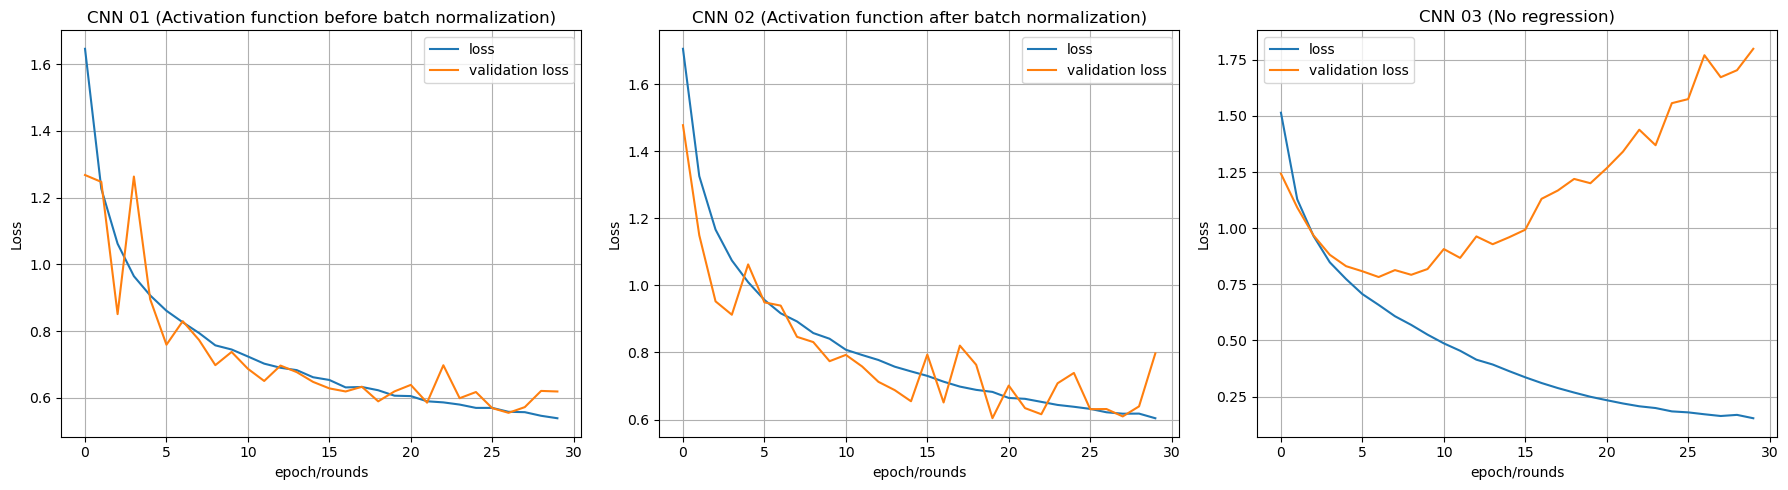

In [22]:
fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(18, 5))

# CNN 01
ax1.plot(cnn_history_01.history["loss"], label="loss")
ax1.plot(cnn_history_01.history["val_loss"], label="validation loss")
ax1.set_xlabel("epoch/rounds")
ax1.set_ylabel("Loss")
ax1.set_title("CNN 01 (Activation function before batch normalization)")
ax1.legend()
ax1.grid(True)

# CNN 02
ax2.plot(cnn_history_02.history["loss"], label="loss")
ax2.plot(cnn_history_02.history["val_loss"], label="validation loss")
ax2.set_xlabel("epoch/rounds")
ax2.set_ylabel("Loss")
ax2.set_title("CNN 02 (Activation function after batch normalization)")
ax2.legend()
ax2.grid(True)

# CNN 03
ax3.plot(cnn_history_03.history["loss"], label="loss")
ax3.plot(cnn_history_03.history["val_loss"], label="validation loss")
ax3.set_xlabel("epoch/rounds")
ax3.set_ylabel("Loss")
ax3.set_title("CNN 03 (No regression)")
ax3.legend()
ax3.grid(True)

plt.tight_layout()
plt.show()

The biggest difference lies in the <b>generalization ability</b> and <b>overfitting</b> of the models. The first two models utilize regularization (such as Dropout or batch normalization), which allows them to learn to recognize new data reliably. On another hand, the third model (one without regression) "memorizes" the training data, resulting in a massive gap opening up between the training and validation curves.

## 5. Evaluation

### Training and validation accuracy

Now we can evaluate the trained neural network on data it has not trained on, using the test data (X_test, y_test). 

In [16]:
fcn_test_loss, fcn_test_acc = fcn_model.evaluate(X_test, y_test)
cnn_test_loss, cnn_test_acc = cnn_model_01.evaluate(X_test, y_test)

print('\n\n[FCN MODEL] Test accuracy:', fcn_test_acc, '\n[CNN MODEL] Test accuracy: ', cnn_test_acc)

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.4736 - loss: 1.4893
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 17ms/step - accuracy: 0.7784 - loss: 0.6515


[FCN MODEL] Test accuracy: 0.47360000014305115 
[CNN MODEL] Test accuracy:  0.7784000039100647


The FCN model achieved a test accuracy of ~47%, while the best CNN model achieved ~78%. The goal was to get the FCN accuracy over 50%, but instead it stays just a little below so far. The CNN model reached its target accuracy of 75%. 

Next we plot the training and validation accuracy of both models to visualize how the accuracy and loss values have changed during training.

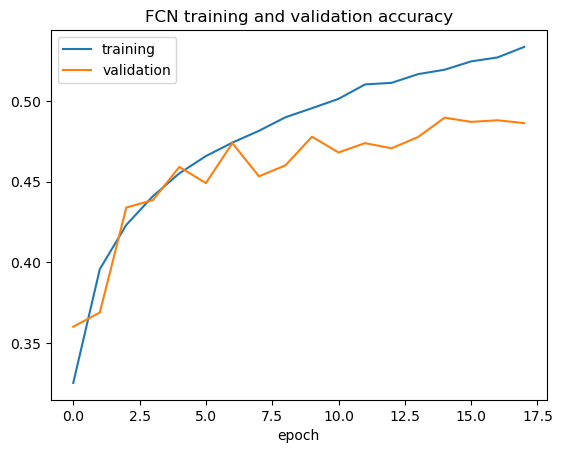

In [17]:
# FCN

plt.plot(fcn_history.history["accuracy"], label="training")
plt.plot(fcn_history.history["val_accuracy"], label="validation")
plt.xlabel("epoch")
plt.title("FCN training and validation accuracy")
plt.legend()
plt.show()

The training accuracy keeps increasing during training, while validation accuracy alternates between small increases and decreases. The validation accuracy stays lower than the training accuracy after epoch 3.

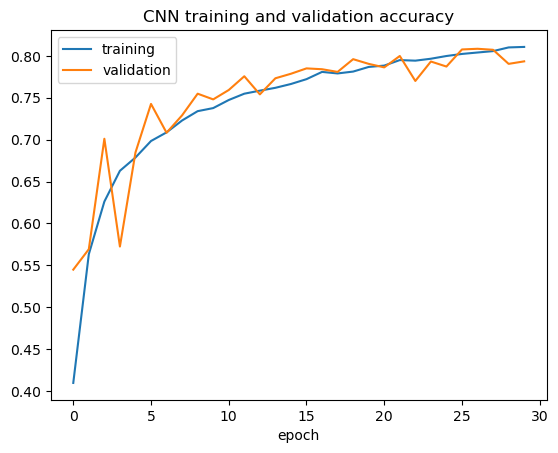

In [18]:
# CNN

plt.plot(cnn_history_01.history["accuracy"], label="training")
plt.plot(cnn_history_01.history["val_accuracy"], label="validation")
plt.xlabel("epoch")
plt.title("CNN training and validation accuracy")
plt.legend()
plt.show()

Similar trend can be seen in the CNN accuracy: the training accuracy keeps increasing steadily, while the validation accuracy alternates. This time the validation accuracy alternates more often than in the FCN model. 

There is a significant drop in validation accuracy at epoch 11, but after that, the accuracy increases again. Towards the end of training, the training and validation accuracies are close to each other.


### Parameter count

Below it's displayed how the neural networks are structured, how data flows through their layers, and how many parameters they have.

In [19]:
print(fcn_model.summary(), cnn_model_02.summary()) # parameter count

Model: "fcn_model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 512)            │     1,573,376 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         2,570 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,121,824 (19.54 MB)

 Trainable params: 1,707,274 (6.51 MB)

 Non-trainable params: 0 (0.00 B)

...

 Total params: 454,048 (1.73 MB)

 Trainable params: 151,242 (590.79 KB)

 Non-trainable params: 320 (1.25 KB)

 Optimizer params: 302,486 (1.15 MB)

None None


The FCN model has 1,707,274 trainable parameters and zero non-trainable parameters. It has four layers. 
The CNN model has 151,242 trainable parameters, 320 non-trainable parameters, and 16 layers.  

Although the CNN has more layers, it has significantly fewer parameters than the FCN. This difference is due to the architectures of the models. The FCN has connections between every neuron in two adjacent layers, requiring a separate weight for each connection. In turn, the CNN uses the same filter with the same weights in different parts of the image.

### Training and validation losses

Using code plotting we can see how well the neural networks learn and whether they might be overfitting. Ideally, both losses decrease as training progresses. 

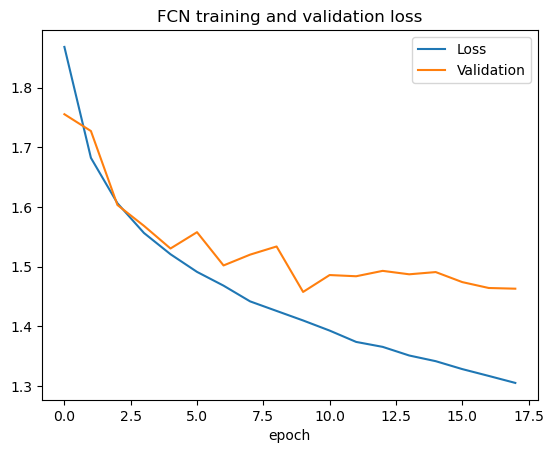

In [23]:
#FCN

plt.plot(fcn_history.history["loss"], label="Loss")
plt.plot(fcn_history.history["val_loss"], label="Validation")
plt.xlabel("epoch")
plt.title("FCN training and validation loss")
plt.legend()
plt.show()

Both curves of FCN seem to decrease steadily until epoch 3 is reached. There the validation loss begins to increase, before it decreases again at epoch 6. After that, the validation loss increases and decreases alternately. The validation loss stays higher than the training loss after epoch 3. However, the difference is relatively small. This may indicate small overfitting. 

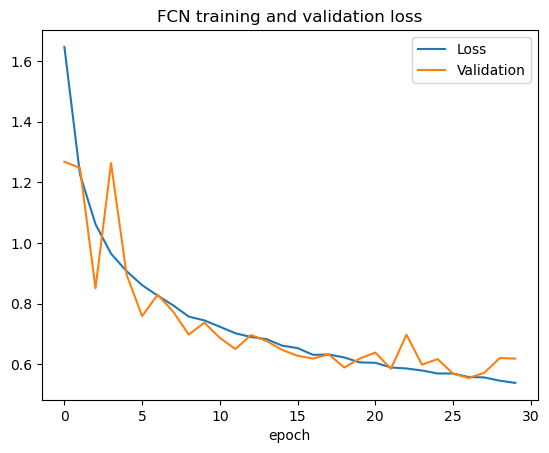

In [24]:
#CNN

plt.plot(cnn_history_01.history["loss"], label="Loss")
plt.plot(cnn_history_01.history["val_loss"], label="Validation")
plt.xlabel("epoch")
plt.title("FCN training and validation loss")
plt.legend()
plt.show()

Training and validation losses behave differently in the CNN model. While the training loss decreases steadily during training, the validation loss alternates between increases and decreases. Towards the end of training, the losses are very close to each other. However, the validation loss begins to increase slightly during the final epochs, which could indicate that the model is starting to overfit. 

### Model training time 

The training times were calculated by summing the durations of all epochs reported in the training logs in the Modeling section. The FCN model was trained for 18 epochs in 8 minutes and 4 seconds, and the CNN model was trained for 30 epochs in 41 minutes and 57 seconds. These times are approximate, as the epoch durations in the training log are rounded to the nearest second. The average training time per epoch was approximately 27 seconds for the FCN model, and 84 seconds for the CNN model.  

So, each epoch took approximately 3.1 times longer to train for the CNN model comparing to the FCN model. That may partly be explained by the architecture of the models – The FCN contains four layers, while the CNN model has 16 layers.

### Predictions on test images

Here we check how well the neural network classifies images from the test dataset and displays its prediction alongside the correct answer. It lets you compare what the image actually represents with what the neural network predicts. We compare the first three images of the test set.  

#### FCN

313/313 ━━━━━━━━━━━━━━━━━━━━ 2s 5ms/step


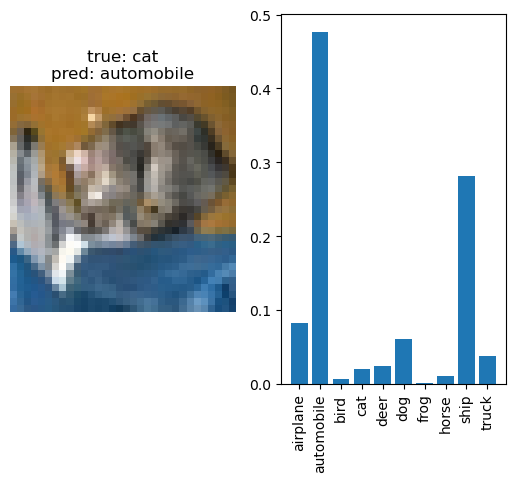

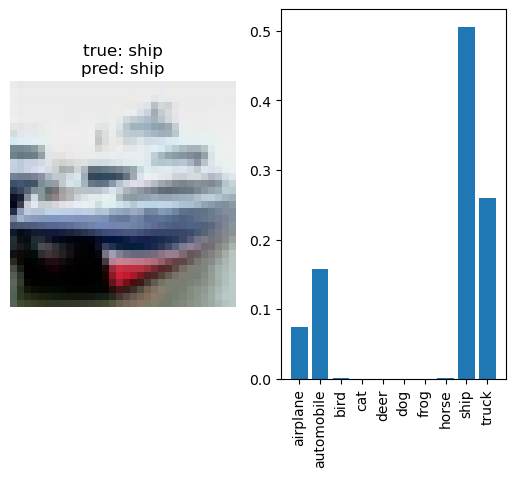

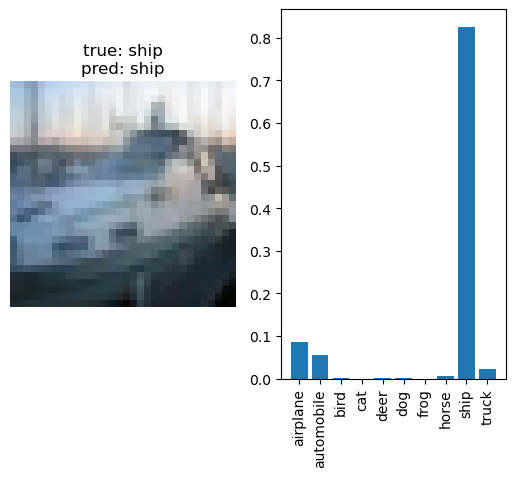

In [25]:
# FCN

class_names = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

probs = fcn_model.predict(X_test)

for i in range(3):
    plt.subplot(1, 2, 1)
    plt.imshow(X_test[i]); plt.axis("off")
    plt.title(f"true: {class_names[y_test[i].argmax()]}\npred: {class_names[probs[i].argmax()]}")
    plt.subplot(1, 2, 2)
    plt.bar(class_names, probs[i]); plt.xticks(rotation=90)
    plt.show()

The FCN model predicted two images correctly, the first image (cat) and the third image (ship) with the probabilites of approximately 0.6 and 0.55. The second image was incorrectly predicted as a truck, while the true class was ship. The FCN model seems to be a little unsure about the predictions, since the predicted probabilites are quite low. In all three images, the probability is distributed across multiple classes. For the incorrectly classified image, the propabilites of the truck and ship classes were close to each other, which may explain the wrong prediction.

#### CNN

313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step


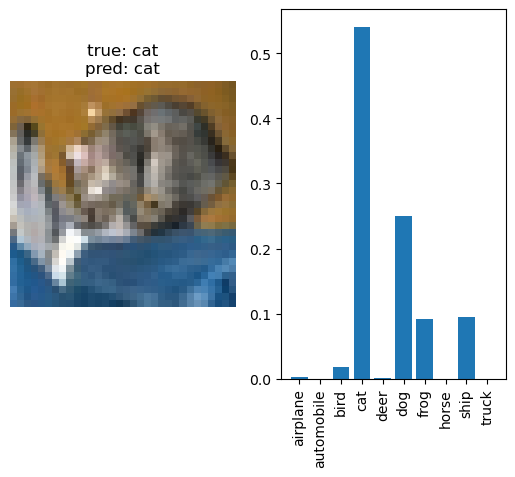

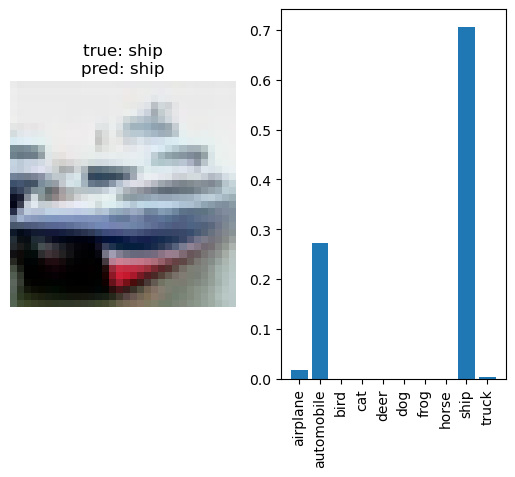

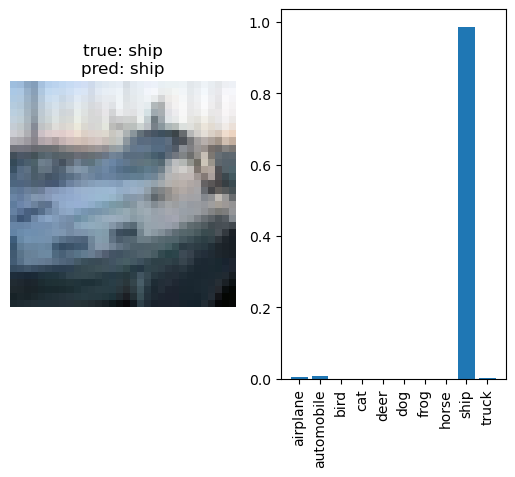

In [26]:
# CNN

class_names = ["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]

probs = cnn_model_01.predict(X_test)

for i in range(3):
    plt.subplot(1, 2, 1)
    plt.imshow(X_test[i]); plt.axis("off")
    plt.title(f"true: {class_names[y_test[i].argmax()]}\npred: {class_names[probs[i].argmax()]}")
    plt.subplot(1, 2, 2)
    plt.bar(class_names, probs[i]); plt.xticks(rotation=90)
    plt.show()

The second CNN model classified all three images correctly. The second and third images had high probabilities of approximately 0.8. The first image (cat) had lower probability of around 0.6.

Compared to the FCN model, the CNN model seems to be more confident in its predictions. Unlike the FCN model, the CNN model does not distribute the probability across many classes. Instead, the probability is concentrated on one or two classes.  

The CNN's better performance compared to the FCN may partly be explained by its more confident predictions.

<h2>6. Deployment</h2>

Based on the results, the CNN model is a better choice for image classification. It achieved a test accuracy of 78.95%, reaching our realistic goal of 75–80%. The FCN model achieved 49.97%, which was slightly below its expected accuracy of 50–55%. 

Although the CNN model took longer to train, it achieved higher accuracy and performed better on the selected test images. The CNN model could be used in a simple application to classify images into the ten CIFAR-10 classes. However, the model still makes mistakes, so it would not be reliable enough for situations where high accuracy is required. Also, since the model was trained on small 32×32 images, its performance on real-world images has not been tested. 

For future development, we recommend testing different model parameters to improve the CNN model's accuracy. It would also be useful to test the model on new images outside the CIFAR-10 dataset. Further testing would be needed before using the model in practice.